In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Load the dataset
file_path = "mauna_loa_co2_monthly_mean_data.csv"

# Skip metadata rows
df = pd.read_csv(file_path, skiprows=40)

# Assign column names
df.columns = [
    'year',
    'month',
    'decimal_date',
    'average',
    'deseasonalized',
    'ndays',
    'sdev',
    'unc'
]

# Create date column
df['date'] = pd.to_datetime(
    df[['year', 'month']].assign(day=1)
)

# Set date as index
df.set_index('date', inplace=True)

# Convert CO₂ values to numeric
df['average'] = pd.to_numeric(df['average'], errors='coerce')

# Remove missing values
co2 = df['average'].dropna()

print(co2.head())

date
1958-03-01    315.71
1958-04-01    317.45
1958-05-01    317.51
1958-06-01    317.27
1958-07-01    315.87
Name: average, dtype: float64


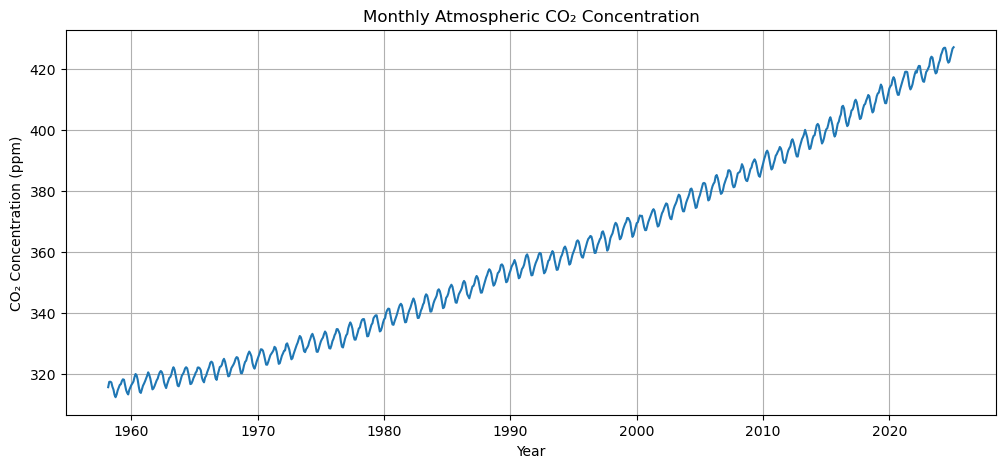

In [2]:
plt.figure(figsize=(12, 5))

plt.plot(co2)

plt.title('Monthly Atmospheric CO₂ Concentration')
plt.xlabel('Year')
plt.ylabel('CO₂ Concentration (ppm)')
plt.grid(True)

plt.show()

In [3]:
moving_average = co2.rolling(window=12).mean()

print(moving_average.head(15))

date
1958-03-01           NaN
1958-04-01           NaN
1958-05-01           NaN
1958-06-01           NaN
1958-07-01           NaN
1958-08-01           NaN
1958-09-01           NaN
1958-10-01           NaN
1958-11-01           NaN
1958-12-01           NaN
1959-01-01           NaN
1959-02-01    315.370000
1959-03-01    315.448333
1959-04-01    315.470833
1959-05-01    315.535833
Name: average, dtype: float64


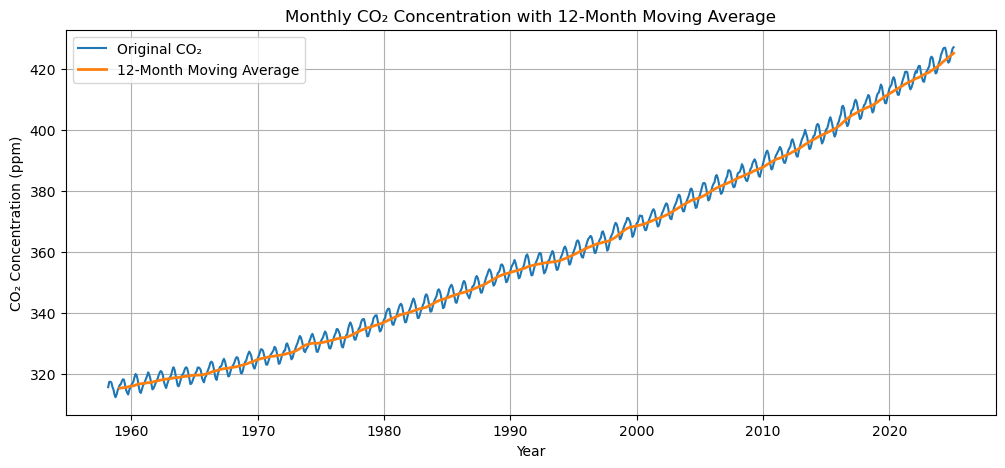

In [4]:
plt.figure(figsize=(12, 5))

plt.plot(co2, label='Original CO₂')
plt.plot(
    moving_average,
    label='12-Month Moving Average',
    linewidth=2
)

plt.title('Monthly CO₂ Concentration with 12-Month Moving Average')
plt.xlabel('Year')
plt.ylabel('CO₂ Concentration (ppm)')
plt.legend()
plt.grid(True)

plt.show()

In [5]:
decomposition = seasonal_decompose(
    co2,
    model='additive',
    period=12
)

print(decomposition)

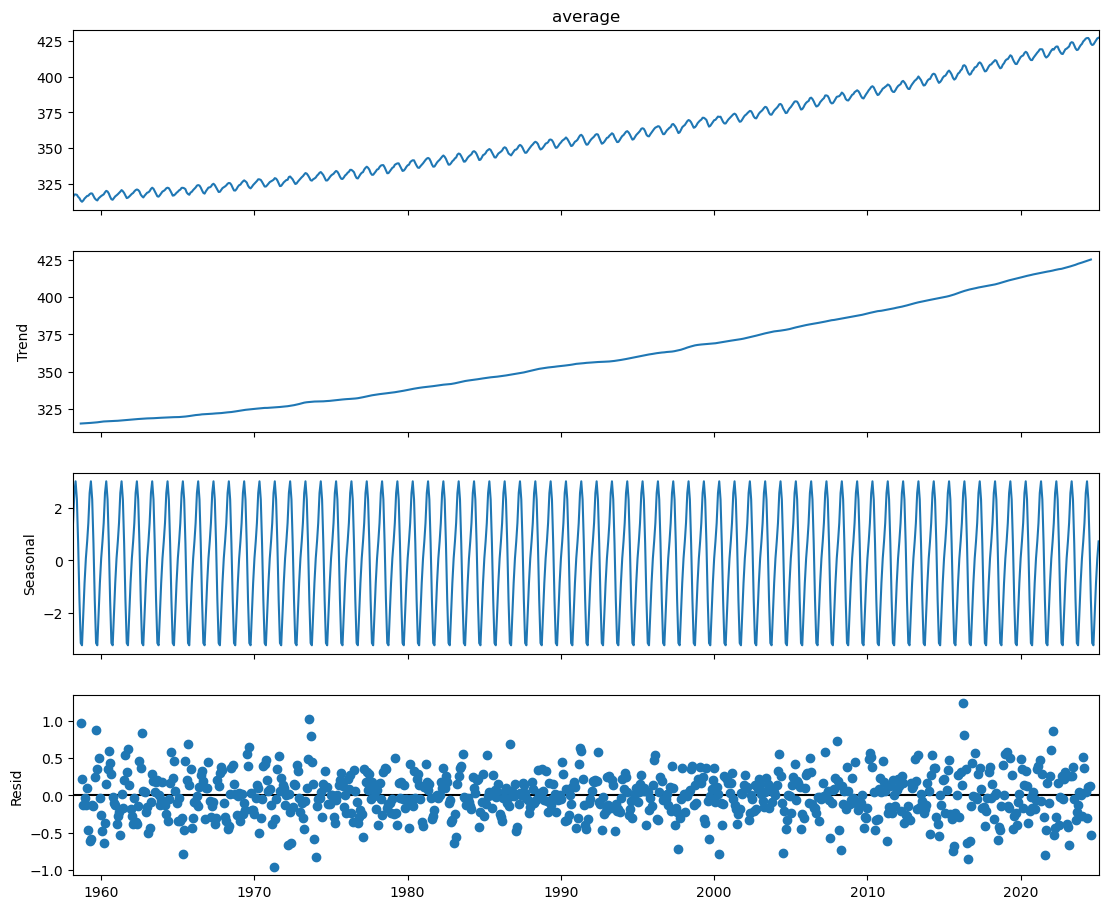

In [6]:
fig = decomposition.plot()

fig.set_size_inches(12, 10)

plt.show()

In [7]:
trend = decomposition.trend

print(trend.dropna().head())

date
1958-09-01    315.409167
1958-10-01    315.459583
1958-11-01    315.503333
1958-12-01    315.572500
1959-01-01    315.637083
Name: trend, dtype: float64


In [8]:
seasonal = decomposition.seasonal

print(seasonal.head(12))

date
1958-03-01    1.433496
1958-04-01    2.585226
1958-05-01    3.031792
1958-06-01    2.335750
1958-07-01    0.661331
1958-08-01   -1.514067
1958-09-01   -3.170601
1958-10-01   -3.255658
1958-11-01   -2.049932
1958-12-01   -0.863966
1959-01-01    0.076969
1959-02-01    0.729658
Name: seasonal, dtype: float64


In [9]:
residual = decomposition.resid

print(residual.dropna().head())

date
1958-09-01    0.971434
1958-10-01    0.216074
1958-11-01   -0.123402
1958-12-01   -0.038534
1959-01-01   -0.134052
Name: resid, dtype: float64


In [10]:
seasonal_effect = seasonal.groupby(
    seasonal.index.month
).mean()

month_names = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

seasonal_table = pd.DataFrame({
    'Month': month_names,
    'Average Seasonal Effect': seasonal_effect.values
})

print(seasonal_table)

        Month  Average Seasonal Effect
0     January                 0.076969
1    February                 0.729658
2       March                 1.433496
3       April                 2.585226
4         May                 3.031792
5        June                 2.335750
6        July                 0.661331
7      August                -1.514067
8   September                -3.170601
9     October                -3.255658
10   November                -2.049932
11   December                -0.863966


In [11]:
monthly_average = co2.groupby(
    co2.index.month
).mean()

monthly_average.index = month_names

print(monthly_average)

January      360.565373
February     361.350299
March        360.516119
April        361.812687
May          362.390597
June         361.838955
July         360.306567
August       358.287463
September    356.752836
October      356.810299
November     358.155821
December     359.483433
Name: average, dtype: float64


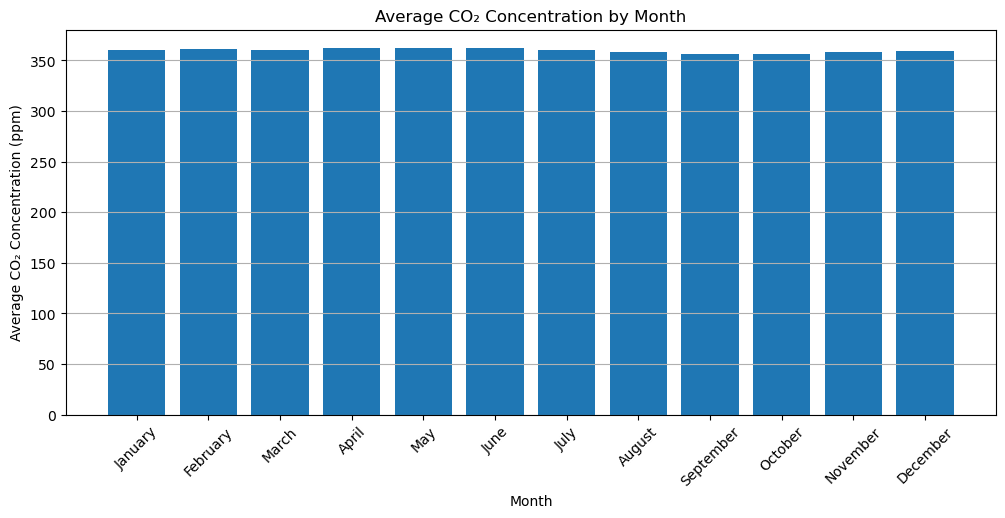

In [12]:
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_average.index,
    monthly_average.values
)

plt.title('Average CO₂ Concentration by Month')
plt.xlabel('Month')
plt.ylabel('Average CO₂ Concentration (ppm)')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.show()